# Known-site check: can public satellite data see Valeriana?

Exploration only. We take one well-documented "lost city" found in lidar and ask what four public, mostly-NASA data sources show over the same ~5 × 5 km box. The answer tells us which sources are worth using to look for *unknown* sites.

**Run it (one command, from the repo root):**

```bash
uv run --no-project --python 3.12 --with-requirements requirements.txt jupyter nbconvert --to notebook --execute --inplace notebooks/known-site-check.ipynb
```

Downloads are cached in `data/raw/known-site/` (git-ignored). Figures go to `figures/known-site/`. Nothing here needs an account or key except the optional GEDI footprint step (section 4b), which runs only if NASA Earthdata credentials are already set up outside the repo.

## The site and the paper

> Auld-Thomas, L., Canuto, M. A., Velázquez Morlet, A., Estrada-Belli, F., Chatelain, D., Matadamas, D., Pigott, M. & Fernández Díaz, J. C. (2024). Running out of empty space: environmental lidar and the crowded ancient landscape of Campeche, Mexico. *Antiquity* 98(401): 1340–1358. https://doi.org/10.15184/aqy.2024.148 (open access, CC BY 4.0).

Checked against the paper itself (PDF, pages 1342–1347):

| Fact | What the paper says |
|---|---|
| Lidar source | Collected in 2013 by the Mexican firm CartoData (Riegl LMS-Q780) for the Alianza M-REDD+ forest-carbon project (The Nature Conservancy, Mexico); processed by Woods Hole Research Center. **Not** NASA G-LiHT. |
| Reprocessing | Point clouds re-classified with NCALM archaeology settings; DTM at 1 m per pixel, ground-point density 5.01 points/m². |
| Where Valeriana is | "Block 2", next to the villages of Dos Lagunas and Bel-Há on highway CAM 269, Calakmul municipality, Campeche. Named after an adjacent freshwater lagoon. |
| Coordinates | **None given.** Only maps with scale bars (Figs 1, 3, 4). |
| Published extent | Block 2 is 16.66 km² (Table 1), with 1,732 structures (104 per km²). Settlement and farm works fill the whole block. |
| Structure | Two hubs of monumental architecture 2 km apart, joined by dense settlement. The larger hub (in the block's north-east corner) has enclosed plazas, a causeway, temple pyramids, a ballcourt, a dammed reservoir and a probable E-Group. |
| Beyond the block | The city runs past the edge of the survey, likely at least 5 km further north (Transect 2 shows the same density). |
| Ground check | None yet; "no field validation" of this analysis has taken place. |
| Structure heights | Not given in the paper. |

**Why this site:** the paper is open access, the data was "found" (collected for forestry, not archaeology), and it is the same region as this project's v1. The other candidates (Caracol, Upano) were not checked here.

## How we got an outline (no coordinates are published)

The paper prints no coordinates, so we **georeference its Figure 3** ourselves:

1. Measure the lidar block's edges and the 500 m scale bar in Figure 3 (pixels), which gives the block size in metres.
2. Turn the figure's terrain colouring (orange = slopes, pale = flat) into a slope proxy and cross-correlate it with SRTM slope over an 18 × 18 km search area. The best match gives the block's north-west corner.
3. Check by eye that the village, the highway and the side road in Figure 3 sit on the same features in Sentinel-2 (figure `00-georef-check.png`).
4. Trace the monumental core from Figure 4 (100 m scale bar; it shares the block's north and east edges) and the second hub from Figure 3.

Everything drawn as "site outline" below is **our digitisation of the paper's maps, not a published polygon**. Expected error is about ±100–150 m (see the check figure).

> ⚠️ **Sensitivity.** The authors chose not to print coordinates. This notebook derives them. Decide before pushing it or its figures to the public repo (`amalmehta/HiddenCities`).

In [1]:
# Setup
import io, json, os, gzip, hashlib, math, urllib.parse, urllib.request, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from matplotlib.patches import Polygon as MplPolygon, Rectangle
from PIL import Image
import pypdf
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds
from pyproj import Transformer
from scipy import ndimage, signal
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw" / "known-site"          # git-ignored downloads
FIG = ROOT / "figures" / "known-site"
RAW.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
UA = {"User-Agent": "HiddenCitiesResearch/0.1 (open research script)"}
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def get(url, path=None, data=None, headers=None, timeout=300):
    # Download once and cache. Returns bytes (or the cached file's bytes).
    if path is not None and Path(path).exists():
        return Path(path).read_bytes()
    req = urllib.request.Request(url, data=data, headers={**UA, **(headers or {})})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        blob = r.read()
    if path is not None:
        Path(path).write_bytes(blob)
    return blob

UTM = "EPSG:32616"                                   # WGS84 / UTM 16N, metres
to_ll = Transformer.from_crs(UTM, "EPSG:4326", always_xy=True)
to_utm = Transformer.from_crs("EPSG:4326", UTM, always_xy=True)
print("root:", ROOT)

root: /Users/amalmehta/Desktop/Amals Work/2026/2026_projects/find hidden cities artifacts from nasa + ground data


## Parameters

Every number we chose ourselves, with its label:

- **FROM PAPER** – read from Auld-Thomas et al. 2024.
- **MEASURED** – measured by us from the paper's figures (pixel positions), so it carries reading error.
- **DECIDED** – a choice for this check, not a fact.
- **INVENTED** – a starting guess with no source; change it freely.

In [2]:
PAPER_PDF_URL = ("https://www.cambridge.org/core/services/aop-cambridge-core/content/view/"
                 "FFDB435047017853F26CFC5D8804B08D/S0003598X24001480a.pdf/"
                 "running-out-of-empty-space-environmental-lidar-and-the-crowded-ancient-landscape-of-campeche-mexico.pdf")
BLOCK2_AREA_KM2 = 16.66        # FROM PAPER, Table 1
HUB_SPACING_KM = 2.0           # FROM PAPER, p. 1346: two monumental hubs 2 km apart

# Figure 3 (PDF page 7) and Figure 4 (page 8), pixel positions in the embedded images
FIG3_SCALEBAR_M = 500          # FROM PAPER (scale bar label)
FIG4_SCALEBAR_M = 100          # FROM PAPER (scale bar label)
FIG4_SCALEBAR_PX = (26, 132)   # MEASURED: ends of the 100 m bar in Fig 4
FIG4_LIDAR_EAST_PX = 1504      # MEASURED: 'Limit of lidar survey' right edge in Fig 4 (= block east edge)
FIG4_LIDAR_NORTH_PX = 76       # MEASURED: top edge in Fig 4 (= block north edge)
# Monumental core traced from Fig 4 (plazas, pyramids, E-Group, ballcourt), pixel polygon
CORE_FIG4_PX = [(600, 150), (1330, 150), (1330, 340), (1000, 340), (1000, 560), (840, 560), (840, 340), (600, 340)]  # MEASURED, by eye
# Second monumental hub (causeway group) traced from Fig 3, pixel box
HUB2_FIG3_PX = [(1195, 585), (1375, 585), (1375, 715), (1195, 715)]   # MEASURED, by eye

# Georeferencing search
SEARCH_NW_UTM = (246000, 2104000)   # DECIDED: 18 x 18 km search area around Bel-Ha / Laguna Valeriana (OSM)
SEARCH_SIZE_M = 18000               # DECIDED
GRID_M = 30                          # DECIDED: work at SRTM resolution

# Study box
BOX_SIZE_M = 5000                    # DECIDED (task): ~5 x 5 km, centred on Block 2

# Display and analysis choices
HILLSHADE_AZ, HILLSHADE_ALT = 315, 45   # INVENTED: conventional NW light
VERT_EXAG = 3                            # INVENTED: for 30 m SRTM hillshade
RELIEF_WINDOW_M = 300                    # INVENTED: 'local relief' = height minus mean over this window
S2_DATES = "2016-01-01T00:00:00Z/2025-12-31T23:59:59Z"   # DECIDED: whole archive, then pick the clearest scene
S2_MAX_CLOUD = 5                          # INVENTED: % cloud for the scene list
S2_DRY_MONTHS = (2, 3, 4, 5)             # DECIDED: dry season, leaf-off-ish forest shows the most ground
GEDI_QUALITY_ONLY = True                  # DECIDED: keep shots with quality_flag == 1 and degrade_flag == 0

## 1. Georeference the paper's Figure 3

Download the paper (cached), extract Figures 3 and 4, measure the lidar block and the scale bar, then find where the block's terrain best matches SRTM.

In [3]:
pdf_path = RAW / "auld-thomas-2024-antiquity.pdf"
get(PAPER_PDF_URL, pdf_path)
reader = pypdf.PdfReader(pdf_path)
def page_image(pageno):
    im = reader.pages[pageno - 1].images[0]
    return np.asarray(Image.open(io.BytesIO(im.data)).convert("RGB"))
fig3, fig4 = page_image(7), page_image(8)
print("Fig 3", fig3.shape, " Fig 4", fig4.shape)

def first_jump(profile, lo, hi):
    return lo + int(np.argmax(np.abs(np.diff(profile[lo:hi])))) + 1

# Block edges: the lidar render is bright; the satellite background is dark green.
bright = fig3.astype(int).sum(2) > 420
cols, rows = bright[300:900].mean(0), bright[:, 600:1200].mean(1)
F3_W, F3_E = first_jump(cols, 250, 400), first_jump(cols, 1400, 1550) - 1
F3_N, F3_S = first_jump(rows, 20, 120), first_jump(rows, 1050, 1150) - 1
# Scale bar: the longest unbroken dark horizontal run in the bottom-left legend (the north arrow is a separate run)
legend = fig3[1080:1130, 0:270].astype(int).sum(2) < 200
def longest_run(row):
    best, start = (0, 0, -1), None
    for x, v in enumerate(list(row) + [False]):
        if v and start is None: start = x
        if not v and start is not None:
            best = max(best, (x - start, start, x - 1)); start = None
    return best
F3_BAR_PX = max(longest_run(r) for r in legend)[1:]
MPP3 = FIG3_SCALEBAR_M / (F3_BAR_PX[1] - F3_BAR_PX[0])              # metres per figure pixel
BLOCK_W_M, BLOCK_H_M = (F3_E - F3_W) * MPP3, (F3_S - F3_N) * MPP3
print(f"Fig 3 block px: W={F3_W} E={F3_E} N={F3_N} S={F3_S}; scale bar px {F3_BAR_PX} -> {MPP3:.3f} m/px")
print(f"Block size from figure: {BLOCK_W_M:.0f} x {BLOCK_H_M:.0f} m = {BLOCK_W_M*BLOCK_H_M/1e6:.2f} km2 "
      f"(paper Table 1: {BLOCK2_AREA_KM2} km2; difference {100*(BLOCK_W_M*BLOCK_H_M/1e6/BLOCK2_AREA_KM2-1):+.1f}%)")

Fig 3 (1157, 1583, 3)  Fig 4 (1154, 1583, 3)
Fig 3 block px: W=331 E=1451 N=57 S=1104; scale bar px (23, 157) -> 3.731 m/px
Block size from figure: 4179 x 3907 m = 16.33 km2 (paper Table 1: 16.66 km2; difference -2.0%)


**SRTM tile.** We use the Tilezen/Mapzen "skadi" mirror of SRTM 1 arc-second (≈30 m) on AWS Open Data, which needs no login. NASA's own copy (SRTMGL1 v3, LP DAAC) needs an Earthdata account. **Assumption:** for this 1° tile the mirror is plain SRTM; Tilezen blends other sources only where SRTM has gaps.

In [4]:
srtm_hgt = RAW / "N18W090.hgt"
if not srtm_hgt.exists():
    gz = get("https://s3.amazonaws.com/elevation-tiles-prod/skadi/N18/N18W090.hgt.gz")
    srtm_hgt.write_bytes(gzip.decompress(gz))

def srtm_grid(x0, y1, nx, ny, res=GRID_M):
    # SRTM resampled (bilinear) onto a north-up UTM grid; returns array and transform
    dst = np.zeros((ny, nx), np.float32); tr = from_origin(x0, y1, res, res)
    with rasterio.open(srtm_hgt) as d:
        reproject(rasterio.band(d, 1), dst, dst_transform=tr, dst_crs=UTM, resampling=Resampling.bilinear)
    return dst, tr

n = SEARCH_SIZE_M // GRID_M
search_dem, _ = srtm_grid(SEARCH_NW_UTM[0], SEARCH_NW_UTM[1], n, n)
gy, gx = np.gradient(search_dem, GRID_M)
srtm_slope = ndimage.uniform_filter(np.hypot(gx, gy), 3)

# Figure 3 slope proxy: orange/red minus blue, averaged to 30 m cells
blk = fig3[F3_N:F3_S, F3_W:F3_E].astype(float)
orange = blk[..., 0] - blk[..., 2]
f = GRID_M / MPP3
templ = ndimage.zoom(ndimage.uniform_filter(orange, int(round(f))), 1 / f, order=1)
templ = (templ - templ.mean()) / templ.std()

# Normalised cross-correlation for every possible NW-corner position
ones = np.ones_like(templ); N = templ.size
mu = signal.correlate(srtm_slope, ones, mode="valid") / N
sd = np.sqrt(np.maximum(signal.correlate(srtm_slope**2, ones, mode="valid") / N - mu**2, 1e-12))
ncc = signal.correlate(srtm_slope, templ, mode="valid") / N / sd
iy, ix = np.unravel_index(np.argmax(ncc), ncc.shape)
NW = (int(SEARCH_NW_UTM[0] + ix * GRID_M), int(SEARCH_NW_UTM[1] - iy * GRID_M))
peak_z = (ncc.max() - ncc.mean()) / ncc.std()
second = np.sort(ncc[np.hypot(*np.meshgrid(np.arange(ncc.shape[1]) - ix, np.arange(ncc.shape[0]) - iy)) > 10].ravel())[-1]
print(f"Best match NW corner (UTM16N): {NW}, NCC = {ncc.max():.3f} ({peak_z:.1f} SD above the mean); "
      f"best value >300 m away = {second:.3f}")

Best match NW corner (UTM16N): (252390, 2091760), NCC = 0.416 (6.1 SD above the mean); best value >300 m away = 0.282


In [5]:
# Site geometry in UTM 16N
W, N_ = NW
E, S_ = W + BLOCK_W_M, N_ - BLOCK_H_M
block = [(W, N_), (E, N_), (E, S_), (W, S_)]
MPP4 = FIG4_SCALEBAR_M / (FIG4_SCALEBAR_PX[1] - FIG4_SCALEBAR_PX[0])
core = [(E - (FIG4_LIDAR_EAST_PX - px) * MPP4, N_ - (py - FIG4_LIDAR_NORTH_PX) * MPP4) for px, py in CORE_FIG4_PX]
hub2 = [(W + (px - F3_W) * MPP3, N_ - (py - F3_N) * MPP3) for px, py in HUB2_FIG3_PX]
cen = lambda p: np.mean(np.array(p), 0)
hub_gap = np.hypot(*(cen(core) - cen(hub2)))
cx, cy = (W + E) / 2, (N_ + S_) / 2
BOX = (cx - BOX_SIZE_M / 2, cy - BOX_SIZE_M / 2, cx + BOX_SIZE_M / 2, cy + BOX_SIZE_M / 2)   # x0, y0, x1, y1
BOX_LL = transform_bounds(UTM, "EPSG:4326", *BOX)

lon, lat = to_ll.transform(*cen(core))
print(f"Block 2: {BLOCK_W_M:.0f} x {BLOCK_H_M:.0f} m; monumental core centre ~ {lat:.4f} N, {abs(lon):.4f} W")
print(f"Distance core -> second hub: {hub_gap:.0f} m (paper: {HUB_SPACING_KM} km)")
print("Study box (lon/lat):", [round(v, 4) for v in BOX_LL])

def outline(ax, label=True, color="#ff2d55"):
    # Draw the published extent (our digitisation) on a UTM-coordinate axes
    ax.add_patch(MplPolygon(block, closed=True, fill=False, ec=color, lw=1.8, ls="--",
                            label="Block 2 = mapped extent (16.7 km², Auld-Thomas et al. 2024)" if label else None))
    ax.add_patch(MplPolygon(core, closed=True, fill=False, ec="#ffd60a", lw=1.8,
                            label="monumental core (traced from Fig 4)" if label else None))
    ax.add_patch(MplPolygon(hub2, closed=True, fill=False, ec="#64d2ff", lw=1.8,
                            label="second hub (traced from Fig 3)" if label else None))

def box_axes(ax, title):
    ax.set_xlim(BOX[0], BOX[2]); ax.set_ylim(BOX[1], BOX[3]); ax.set_aspect("equal")
    ax.set_xticks(np.arange(BOX[0], BOX[2] + 1, 1000)); ax.set_yticks(np.arange(BOX[1], BOX[3] + 1, 1000))
    ax.set_xticklabels([f"{i}" for i in range(6)]); ax.set_yticklabels([f"{i}" for i in range(6)])
    ax.set_xlabel("km (box origin = SW corner)"); ax.set_ylabel("km"); ax.set_title(title, fontsize=11)

Block 2: 4179 x 3907 m; monumental core centre ~ 18.9013 N, 89.3161 W
Distance core -> second hub: 1959 m (paper: 2.0 km)
Study box (lon/lat): [-89.3547, 18.8629, -89.3066, 18.9087]


### Check: does the georeferenced figure line up with the ground?

Left: Sentinel-2 true colour, with the block placed by the correlation. Right: the paper's Figure 3 laid over it at 50 % opacity. The village, the highway running south-west and its continuation north-east into the block should sit on the same features. A newer road running south-east into the block appears only in Sentinel-2; it is not in the 2013 lidar.

114 Sentinel-2 L2A scenes in UTM 16N with < 5% cloud; using S2A_16QBF_20240329_0_L2A (2024-03-29, 0.00% cloud)


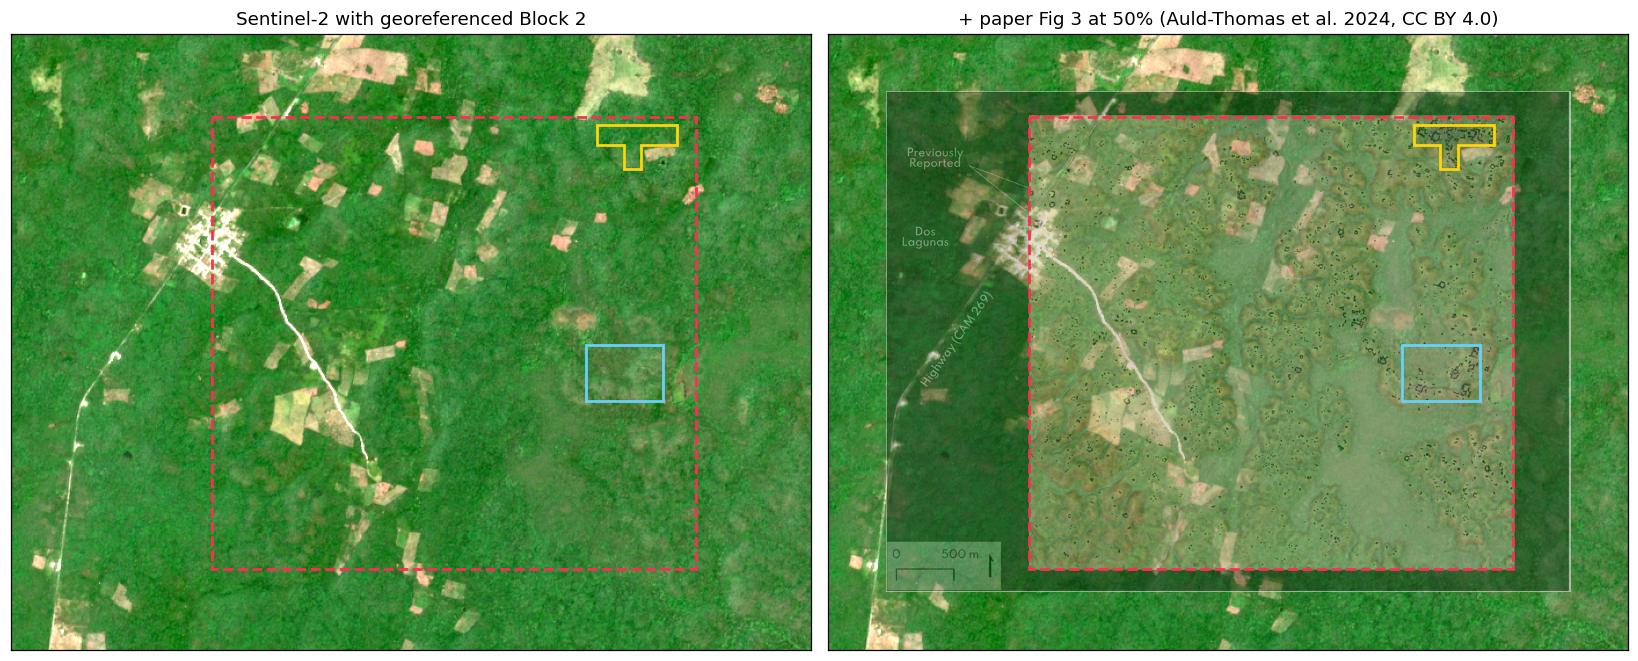

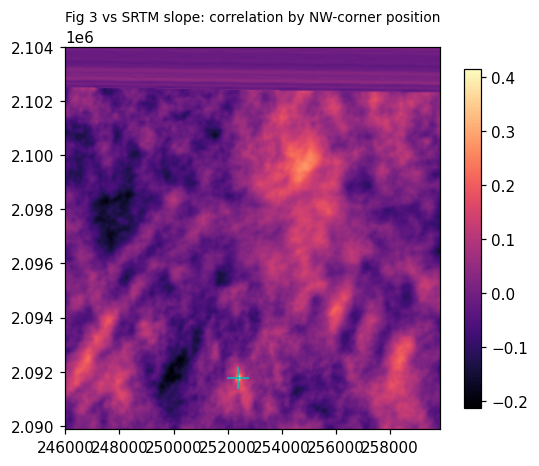

In [6]:
STAC = "https://earth-search.aws.element84.com/v1/search"
def s2_items(bbox_ll, dates=S2_DATES, max_cloud=S2_MAX_CLOUD):
    # All matching items, following the 'next' pages; cached as one file
    q = {"collections": ["sentinel-2-l2a"], "bbox": [round(v, 5) for v in bbox_ll], "datetime": dates,
         "query": {"eo:cloud_cover": {"lt": max_cloud}}, "limit": 100}
    cache = RAW / f"stac_{hashlib.sha1(json.dumps(q, sort_keys=True).encode()).hexdigest()[:12]}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    feats, body = [], q
    while body is not None:
        page = json.loads(get(STAC, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"}))
        feats += page["features"]
        nxt = [l for l in page.get("links", []) if l.get("rel") == "next"]
        body = nxt[0]["body"] if nxt else None
    cache.write_text(json.dumps(feats))
    return feats

def s2_read(item, bands, bounds_utm):
    # Read bands (boundless) for a UTM16 box; the item must be in UTM 16N
    out = []
    for b in bands:
        with rasterio.open(item["assets"][b]["href"]) as d:
            assert d.crs.to_string() == UTM, d.crs
            w = from_bounds(*bounds_utm, d.transform)
            a = d.read(1, window=w, boundless=True, fill_value=0).astype(float)
        rb = (item["assets"][b].get("raster:bands") or [{}])[0]
        # DN -> reflectance (0 = no data). Earth Search flags scenes whose -0.1 offset is already baked in;
        # checked on this scene: forest red DN ~390 (= 0.039), so applying the offset again would go negative.
        off = 0 if item["properties"].get("earthsearch:boa_offset_applied") else rb.get("offset", 0)
        a = np.where(a == 0, np.nan, a * rb.get("scale", 1) + off)
        out.append(a)
    return np.dstack(out)

def stretch(rgb, p=99.5, gamma=0.6):
    v = rgb[np.isfinite(rgb)]
    return np.nan_to_num(np.clip((rgb - np.percentile(v, 0.5)) / (np.percentile(v, p) - np.percentile(v, 0.5)), 0, 1) ** gamma)

items = [f for f in s2_items(BOX_LL) if f["properties"].get("mgrs:utm_zone") == 16]
items.sort(key=lambda f: (int(f["properties"]["datetime"][5:7]) not in S2_DRY_MONTHS, f["properties"]["eo:cloud_cover"],
                          f["properties"].get("s2:nodata_pixel_percentage", 0), f["properties"]["datetime"]))
for s2 in items:                      # first scene that fully covers the box
    if np.isfinite(s2_read(s2, ["red"], BOX)).mean() > 0.995:
        break
print(f"{len(items)} Sentinel-2 L2A scenes in UTM 16N with < {S2_MAX_CLOUD}% cloud; using {s2['id']} "
      f"({s2['properties']['datetime'][:10]}, {s2['properties']['eo:cloud_cover']:.2f}% cloud)")

# Wider view for the check
fx0 = W - F3_W * MPP3; fy1 = N_ + F3_N * MPP3
fx1 = fx0 + fig3.shape[1] * MPP3; fy0 = fy1 - fig3.shape[0] * MPP3
vb = (fx0 - 500, fy0 - 500, fx1 + 500, fy1 + 500)
rgb_wide = stretch(s2_read(s2, ["red", "green", "blue"], vb))
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
for a in axs:
    a.imshow(rgb_wide, extent=[vb[0], vb[2], vb[1], vb[3]])
axs[1].imshow(fig3, extent=[fx0, fx1, fy0, fy1], alpha=0.5)
for a, t in zip(axs, ["Sentinel-2 with georeferenced Block 2", "+ paper Fig 3 at 50% (Auld-Thomas et al. 2024, CC BY 4.0)"]):
    outline(a, label=False); a.set_xlim(vb[0], vb[2]); a.set_ylim(vb[1], vb[3]); a.set_title(t); a.set_xticks([]); a.set_yticks([])
fig.tight_layout(); fig.savefig(FIG / "00-georef-check.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(ncc, cmap="magma", extent=[SEARCH_NW_UTM[0], SEARCH_NW_UTM[0] + ncc.shape[1] * GRID_M,
                                          SEARCH_NW_UTM[1] - ncc.shape[0] * GRID_M, SEARCH_NW_UTM[1]])
ax.plot(*NW, "c+", ms=14); ax.set_title("Fig 3 vs SRTM slope: correlation by NW-corner position", fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.8); fig.savefig(FIG / "00-georef-correlation.png", bbox_inches="tight"); plt.show()

## 2. Source (a): NASA SRTM, 30 m

We fetch SRTM over the box (from the tile already cached), draw a hillshade, and also draw *local relief* (height minus its 300 m mean), which is how this project's lidar detector finds mounds.

,SRTM
box elevation range (m),149–270
"local relief SD, whole box (m)",4.4
mean local relief in core (m),+4.9
"core cells' relief, mean percentile within box",79
share of box at least as high (relief) as the core mean,13%
core cells,168


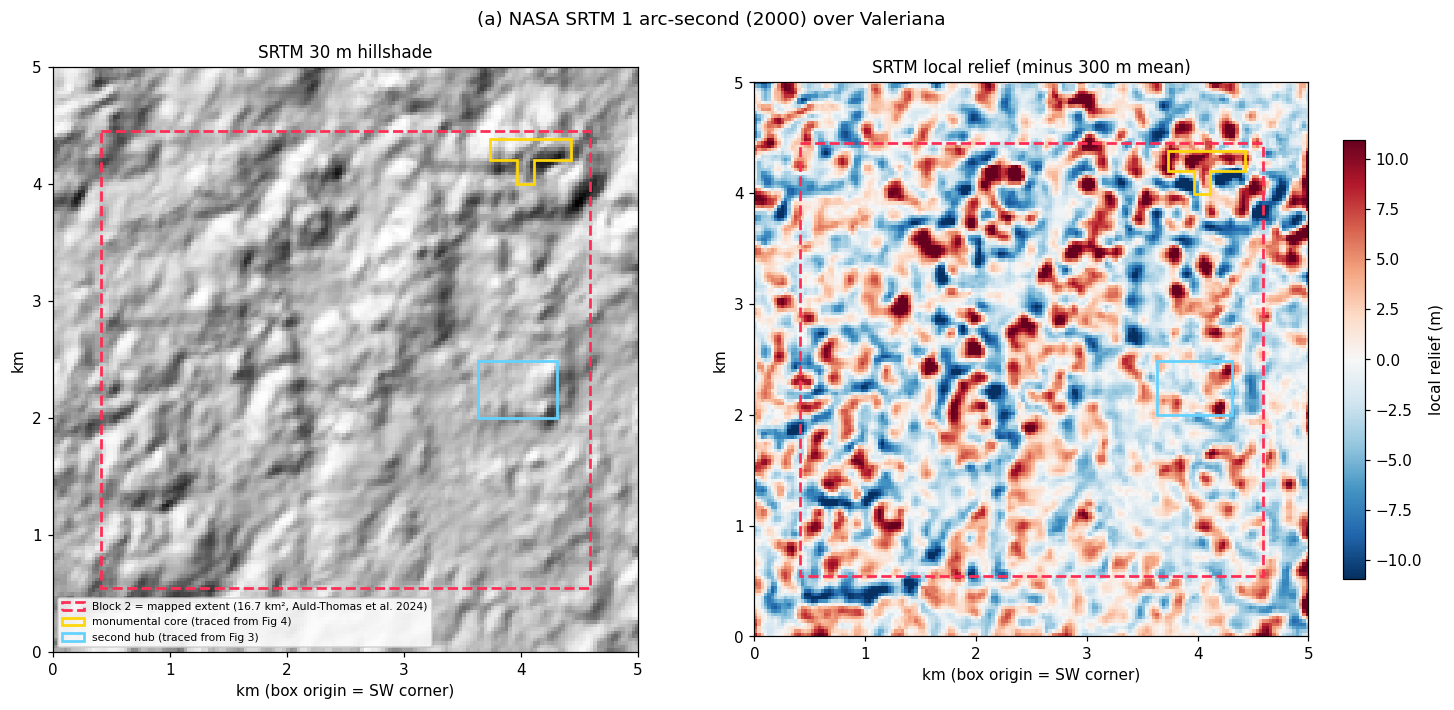

In [7]:
nb = int(BOX_SIZE_M // GRID_M)
dem, dem_tr = srtm_grid(BOX[0], BOX[3], nb, nb)
ls = LightSource(HILLSHADE_AZ, HILLSHADE_ALT)
hs = ls.hillshade(dem, vert_exag=VERT_EXAG, dx=GRID_M, dy=GRID_M)
relief = dem - ndimage.uniform_filter(dem, int(RELIEF_WINDOW_M / GRID_M))
ext = [BOX[0], BOX[2], BOX[1], BOX[3]]

def mask_of(poly, shape, tr):
    from matplotlib.path import Path as MPath
    rr, cc = np.mgrid[0:shape[0], 0:shape[1]]
    xs, ys = tr.c + (cc + 0.5) * tr.a, tr.f + (rr + 0.5) * tr.e
    return MPath(poly).contains_points(np.c_[xs.ravel(), ys.ravel()]).reshape(shape)

core_m = mask_of(core, dem.shape, dem_tr); block_m = mask_of(block, dem.shape, dem_tr)
pct = lambda a, m: 100 * (a[m][:, None] > a.ravel()[None, :]).mean()
srtm_stats = {
    "box elevation range (m)": f"{dem.min():.0f}–{dem.max():.0f}",
    "local relief SD, whole box (m)": f"{relief.std():.1f}",
    "mean local relief in core (m)": f"{relief[core_m].mean():+.1f}",
    "core cells' relief, mean percentile within box": f"{pct(relief, core_m):.0f}",
    "share of box at least as high (relief) as the core mean": f"{100 * (relief >= relief[core_m].mean()).mean():.0f}%",
    "core cells": int(core_m.sum()),
}
display(pd.Series(srtm_stats, name="SRTM").to_frame())

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
axs[0].imshow(hs, cmap="gray", extent=ext)
v = np.percentile(np.abs(relief), 98)
im = axs[1].imshow(relief, cmap="RdBu_r", vmin=-v, vmax=v, extent=ext)
plt.colorbar(im, ax=axs[1], shrink=0.75, label="local relief (m)")
for a, t in zip(axs, ["SRTM 30 m hillshade", f"SRTM local relief (minus {RELIEF_WINDOW_M} m mean)"]):
    outline(a); box_axes(a, t)
axs[0].legend(loc="lower left", fontsize=7, framealpha=0.85)
fig.suptitle("(a) NASA SRTM 1 arc-second (2000) over Valeriana")
fig.tight_layout(); fig.savefig(FIG / "a-srtm.png", bbox_inches="tight"); plt.show()

**Is the site visible in SRTM? No.**

- What you see is the land, not the city: the hills and the flat-bottomed *bajos* (seasonal wetlands) between them. That pattern is real and matches the paper's lidar, which is why the georeferencing works.
- **Feature size it can show:** about 60–90 m across (2–3 cells of 30 m), and only if a feature stands several metres above its surroundings. SRTM's height error over forest is several metres.
- **Why the city can't be seen:** (1) House mounds (about 10–25 m across, measured from Fig 4) are smaller than one cell. (2) SRTM's C-band radar bounces off the forest canopy, not the ground, so the 15–25 m tall forest buries mounds a few metres high. The canopy varies by more than that from place to place. (3) The monumental core (≈700 × 200 m) does read high in local relief, about +5 m (table above). But that is the hilltop it was built on (Fig 4 shows the plazas on a ridge). About a fifth of the box, mostly natural hilltops, reads as high or higher, so SRTM cannot tell the city's core from an empty hill.

## 3. Source (b): NASA GEDI L2A footprints

GEDI is a lidar on the International Space Station (2019–). It fires 25 m footprints about 60 m apart along 8 tracks, which are about 600 m apart. L2A gives ground elevation (`elev_lowestmode`) and canopy heights for each footprint.

**Step 1 (no login needed):** ask NASA's CMR catalogue which L2A granules cross the box.

In [8]:
cmr = ("https://cmr.earthdata.nasa.gov/search/granules.json?short_name=GEDI02_A&version=002&page_size=500&bounding_box="
       + ",".join(f"{v:.5f}" for v in BOX_LL))
granules = json.loads(get(cmr, RAW / "gedi_cmr.json"))["feed"]["entry"]
gran = pd.DataFrame({"granule": [g["title"] for g in granules],
                     "start": [g["time_start"][:10] for g in granules]})
print(f"{len(gran)} GEDI L2A v002 granules have a footprint envelope crossing the box "
      f"({gran.start.min()} to {gran.start.max()}).")
print("Note: CMR matches on coarse granule outlines, so not every granule has shots inside the box.")
gran.head()

28 GEDI L2A v002 granules have a footprint envelope crossing the box (2019-04-29 to 2025-07-06).
Note: CMR matches on coarse granule outlines, so not every granule has shots inside the box.


,granule,start
0,GEDI02_A_2019119172916_O02141_03_T02607_02_003...,2019-04-29
1,GEDI02_A_2019227132211_O03815_02_T01989_02_003...,2019-08-15
2,GEDI02_A_2019277030408_O04584_03_T05453_02_003...,2019-10-04
3,GEDI02_A_2019326073535_O05347_03_T03877_02_003...,2019-11-22
4,GEDI02_A_2020021221442_O06287_02_T04835_02_003...,2020-01-21


**Step 2 (needs a NASA Earthdata login):** the footprint files themselves are on LP DAAC's protected bucket. This cell runs only if credentials are **already** set up outside the repo, either `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` in the environment or a `urs.earthdata.nasa.gov` entry in `~/.netrc`. It never writes or asks for credentials. It streams each granule, keeps only shots inside the box, and caches them to `data/raw/known-site/gedi_box.csv`.

*Status: this code path has not been run yet (no credentials on this machine when the notebook was written).*

GEDI footprints NOT fetched: no Earthdata credentials found (env or ~/.netrc). Skipping step 2.


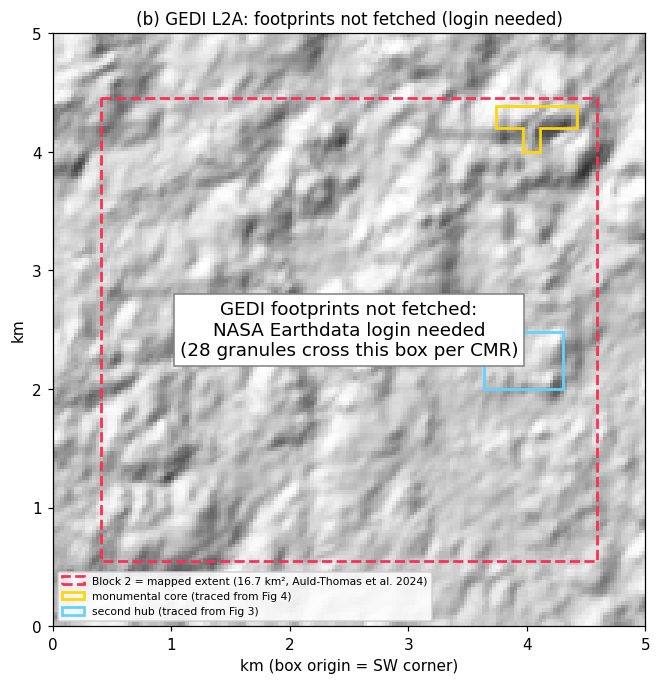

In [9]:
def have_earthdata():
    if os.environ.get("EARTHDATA_USERNAME") and os.environ.get("EARTHDATA_PASSWORD"):
        return "environment"
    netrc = Path.home() / ".netrc"
    if netrc.exists() and "urs.earthdata.nasa.gov" in netrc.read_text():
        return "netrc"
    return None

gedi_csv = RAW / "gedi_box.csv"
gedi = None
if gedi_csv.exists():
    gedi = pd.read_csv(gedi_csv)
elif have_earthdata():
    import earthaccess, h5py
    earthaccess.login(strategy=have_earthdata())
    results = earthaccess.search_data(short_name="GEDI02_A", version="002", bounding_box=tuple(BOX_LL))
    w, s, e, n = BOX_LL
    rows = []
    for res, fobj in zip(results, earthaccess.open(results)):
        with h5py.File(fobj, "r") as h:
            for beam in [k for k in h.keys() if k.startswith("BEAM")]:
                g = h[beam]
                la, lo = g["lat_lowestmode"][:], g["lon_lowestmode"][:]
                idx = np.where((la >= s) & (la <= n) & (lo >= w) & (lo <= e))[0]
                if idx.size == 0:
                    continue
                sl = slice(idx.min(), idx.max() + 1); k = idx - idx.min()
                rows.append(pd.DataFrame({
                    "granule": res["umm"]["GranuleUR"], "beam": beam,
                    "lat": la[idx], "lon": lo[idx],
                    "elev_lowestmode": g["elev_lowestmode"][sl][k],
                    "rh98": g["rh"][sl][k, 98],
                    "quality_flag": g["quality_flag"][sl][k], "degrade_flag": g["degrade_flag"][sl][k],
                    "sensitivity": g["sensitivity"][sl][k]}))
    gedi = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()
    gedi.to_csv(gedi_csv, index=False)
else:
    print("GEDI footprints NOT fetched: no Earthdata credentials found (env or ~/.netrc). Skipping step 2.")

if gedi is not None and len(gedi):
    if GEDI_QUALITY_ONLY:
        gedi = gedi[(gedi.quality_flag == 1) & (gedi.degrade_flag == 0)]
    gx_, gy_ = to_utm.transform(gedi.lon.values, gedi.lat.values)
    gedi = gedi.assign(x=gx_, y=gy_)
    from matplotlib.path import Path as MPath
    gedi["in_block"] = MPath(block).contains_points(np.c_[gedi.x, gedi.y])
    print(f"{len(gedi)} good-quality footprints in the box, {int(gedi.in_block.sum())} inside Block 2")

fig, ax = plt.subplots(figsize=(7.5, 7))
ax.imshow(hs, cmap="gray", extent=ext, alpha=0.8)
if gedi is not None and len(gedi):
    sc = ax.scatter(gedi.x, gedi.y, c=gedi.elev_lowestmode, s=6, cmap="viridis")
    plt.colorbar(sc, ax=ax, shrink=0.75, label="GEDI ground elevation (m, WGS84 ellipsoid)")
    title = "(b) GEDI L2A footprints (25 m) on SRTM hillshade"
else:
    ax.text(0.5, 0.5, "GEDI footprints not fetched:\nNASA Earthdata login needed\n"
            f"({len(gran)} granules cross this box per CMR)", transform=ax.transAxes, ha="center", va="center",
            fontsize=12, bbox=dict(fc="white", ec="0.5"))
    title = "(b) GEDI L2A: footprints not fetched (login needed)"
outline(ax); box_axes(ax, title); ax.legend(loc="lower left", fontsize=7, framealpha=0.85)
fig.savefig(FIG / "b-gedi.png", bbox_inches="tight"); plt.show()

**Is the site visible in GEDI? Not checked yet (needs a login). Expected: partly at best.**

- **Feature size:** each shot measures one 25 m circle. Shots are 60 m apart along a track and tracks are about 600 m apart, so 1 km² gets roughly 100–200 shots over several years. A full map would need about a million 1 m cells.
- **What could show:** a shot that lands on a big pyramid or platform could read a ground height several metres above its neighbours on the same track. That is a hint, not a map. Most house mounds (10–25 m) fall between shots or blur with the ground in a 25 m footprint.
- **Why it can't map the city:** (1) the sampling is too sparse; (2) the ground return under dense canopy is often weak, so many shots fail the quality flags; (3) geolocation error is about 10 m, which is the size of a house mound.
- Once footprints are fetched, the useful test is: do in-core shots have higher `elev_lowestmode` than shots on the same track just outside? Not done here.

## 4. Source (c): Sentinel-2 imagery, 10 m

We use ESA Sentinel-2 L2A (surface reflectance), served as public Cloud-Optimised GeoTIFFs on AWS by Element 84 (Earth Search STAC); no login. We chose Sentinel-2 over Landsat because it is sharper (10 m vs 30 m). We pick the clearest dry-season scene and plot true colour plus NDVI (a greenness index). Some forests over buried stone show as patches of slightly different greenness, so we also plot NDVI minus its local mean.

,Sentinel-2
scene,S2A_16QBF_20240329_0_L2A
date,2024-03-29
"NDVI, forest inside core",0.803
"NDVI, forest elsewhere in box",0.790
"NDVI anomaly SD (forest, box)",0.036
mean NDVI anomaly in core (forest),+0.010


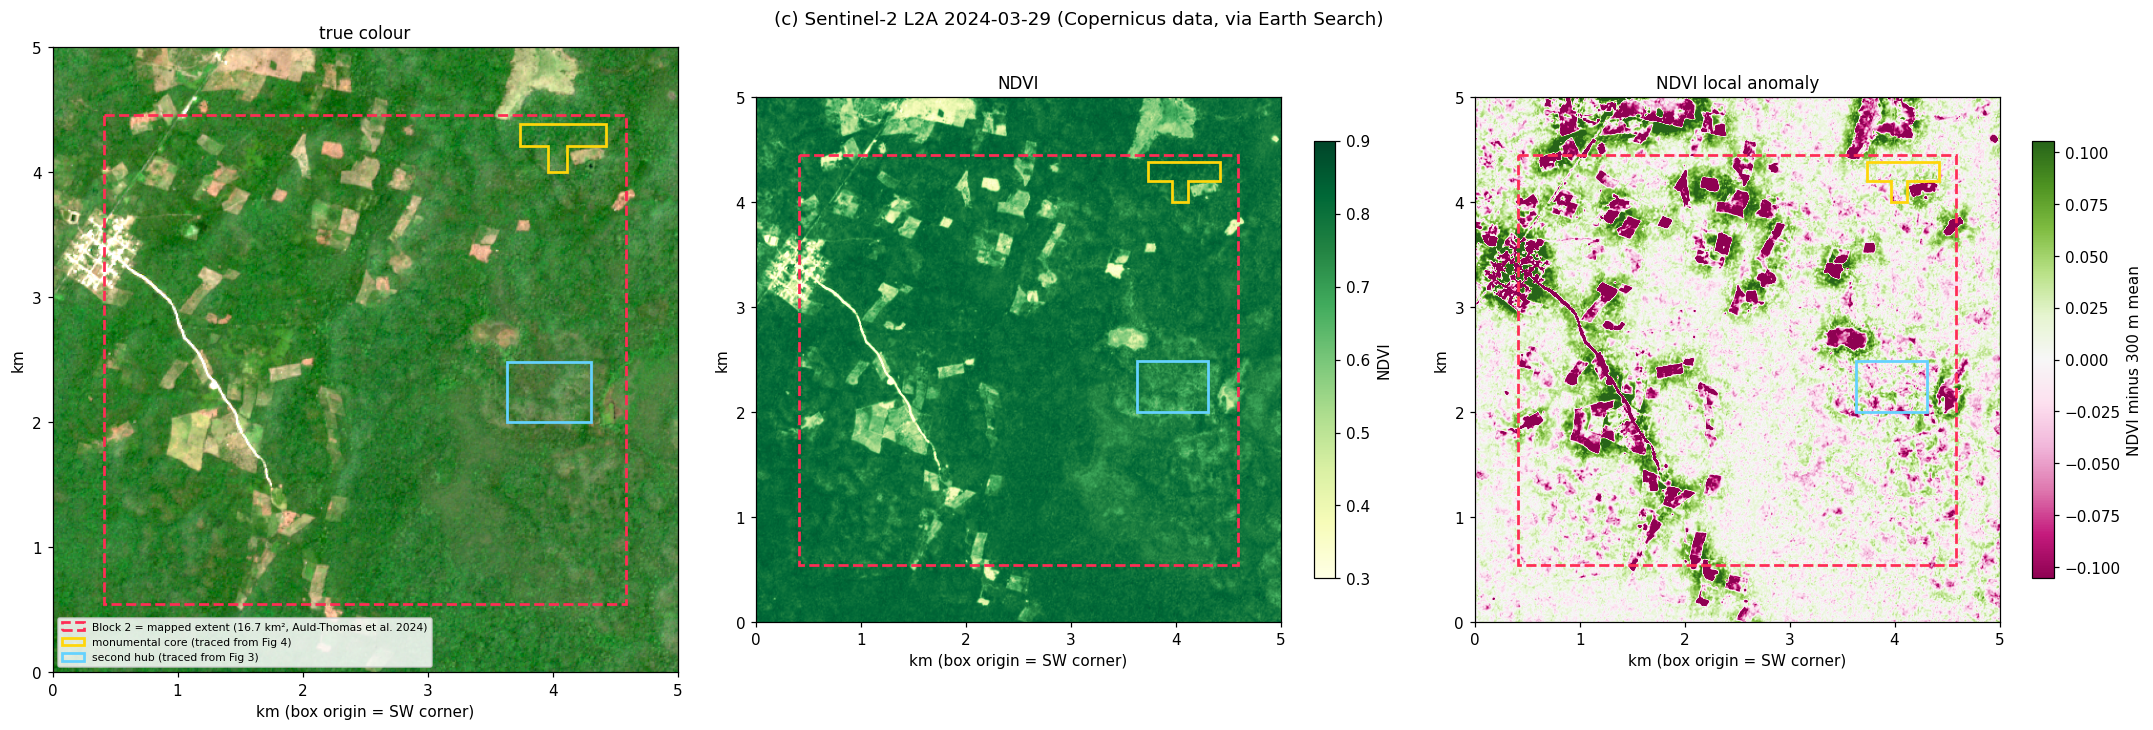

In [10]:
img = s2_read(s2, ["red", "green", "blue", "nir"], BOX)
rgb = stretch(img[..., :3])
red, nir = img[..., 0], img[..., 3]
ndvi = (nir - red) / np.maximum(nir + red, 1e-6)
ndvi_anom = ndvi - ndimage.uniform_filter(ndvi, int(RELIEF_WINDOW_M / 10))
s2_tr = from_origin(BOX[0], BOX[3], 10, 10)
core_m10 = mask_of(core, ndvi.shape, s2_tr); block_m10 = mask_of(block, ndvi.shape, s2_tr)
forest = np.nan_to_num(ndvi) > 0.6                     # INVENTED: 'forest' pixels for a fair comparison
s2_stats = {
    "scene": s2["id"], "date": s2["properties"]["datetime"][:10],
    "NDVI, forest inside core": f"{ndvi[core_m10 & forest].mean():.3f}",
    "NDVI, forest elsewhere in box": f"{ndvi[~block_m10 & forest].mean():.3f}",
    "NDVI anomaly SD (forest, box)": f"{ndvi_anom[forest].std():.3f}",
    "mean NDVI anomaly in core (forest)": f"{ndvi_anom[core_m10 & forest].mean():+.3f}",
}
display(pd.Series(s2_stats, name="Sentinel-2").to_frame())

fig, axs = plt.subplots(1, 3, figsize=(20, 6.5))
axs[0].imshow(rgb, extent=ext)
im1 = axs[1].imshow(ndvi, cmap="YlGn", vmin=0.3, vmax=0.9, extent=ext); plt.colorbar(im1, ax=axs[1], shrink=0.7, label="NDVI")
v = np.percentile(np.abs(ndvi_anom[forest]), 98)
im2 = axs[2].imshow(ndvi_anom, cmap="PiYG", vmin=-v, vmax=v, extent=ext); plt.colorbar(im2, ax=axs[2], shrink=0.7, label="NDVI minus 300 m mean")
for a, t in zip(axs, ["true colour", "NDVI", "NDVI local anomaly"]):
    outline(a); box_axes(a, t)
axs[0].legend(loc="lower left", fontsize=7, framealpha=0.85)
fig.suptitle(f"(c) Sentinel-2 L2A {s2['properties']['datetime'][:10]} (Copernicus data, via Earth Search)")
fig.tight_layout(); fig.savefig(FIG / "c-sentinel2.png", bbox_inches="tight"); plt.show()

**Is the site visible in Sentinel-2? No.**

- **Feature size:** 10 m pixels, so in open ground it could show something about 20–30 m across. Here there is no open ground: the site is under closed forest except for fields and the village at the west edge.
- **What shows:** fields, roads, the village, and the bajo/upland pattern through forest type (bajo forest is lower and wetter, with different greenness). The monumental core does not stand out in true colour, NDVI or NDVI anomaly: see the table above.
- **Why the city can't be seen:** optical sensors see the top of the canopy, and structures 1–10 m high under 15–25 m of forest leave no reliable mark on it. A crop-mark effect (forest on rubble being drier) would need many dates and a known target to tune on; one scene cannot show it.

## 5. Source (d): airborne lidar on OpenTopography

We ask OpenTopography's public catalogue API (no key) which **point-cloud** datasets intersect the box. Its global raster DEMs, such as SRTM and Copernicus, are not airborne lidar and are left out. We then measure how far the nearest NASA G-LiHT 2013 strip is (the strips this project's v1 uses), from the tile outlines on OpenTopography's public bucket.

OpenTopography point-cloud datasets intersecting the box: 0 []
Nearest G-LiHT 2013 tile: 17.9 km from Block 2 (bounding-box distance; strips are narrow, so this is a lower bound)


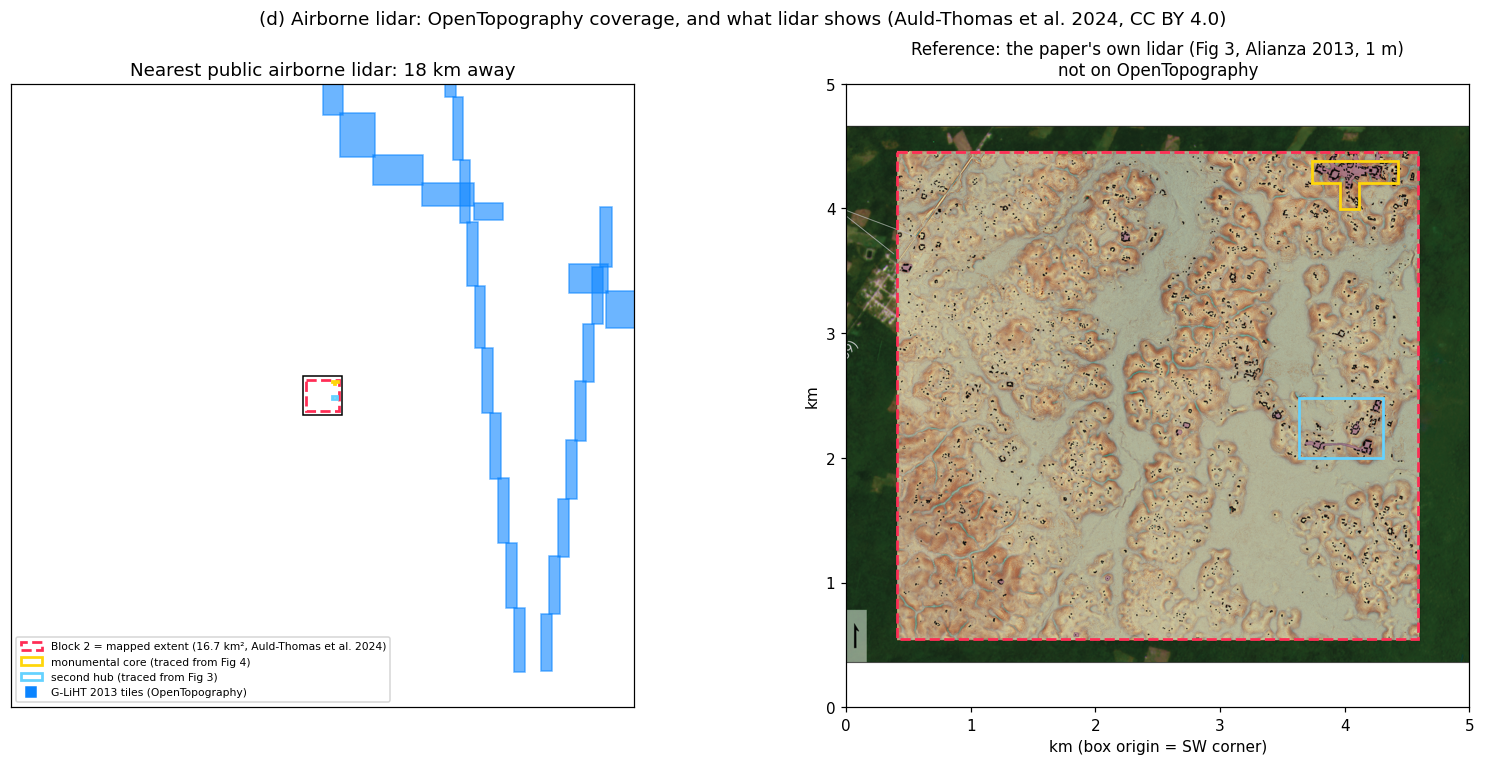

In [11]:
w, s, e, n = BOX_LL
ot_url = (f"https://portal.opentopography.org/API/otCatalog?productFormat=PointCloud&minx={w}&miny={s}&maxx={e}&maxy={n}"
          "&detail=false&outputFormat=json&include_federated=true")
ot = json.loads(get(ot_url, RAW / "ot_catalog_box.json")).get("Datasets", [])
ot_names = [d["Dataset"]["name"] for d in ot]
print(f"OpenTopography point-cloud datasets intersecting the box: {len(ot_names)}", ot_names)

# Nearest G-LiHT 2013 tile (bare-earth reprocessing, public bucket). Reuses the project's cached header list.
sys.path.insert(0, str(ROOT))
from pipeline import fetch as pf
glh = pf.headers("MX13E_Britton")
def dist_to_box(b):
    dx = max(b[0] - E, W - b[2], 0); dy = max(b[1] - N_, S_ - b[3], 0); return math.hypot(dx, dy)
tiles = pd.DataFrame([{"key": h["key"], "d_km": dist_to_box(h["bounds"]) / 1000, "bounds": h["bounds"]} for h in glh])
near = tiles.sort_values("d_km").iloc[0]
print(f"Nearest G-LiHT 2013 tile: {near.d_km:.1f} km from Block 2 (bounding-box distance; strips are narrow, so this is a lower bound)")

fig, axs = plt.subplots(1, 2, figsize=(15, 7))
R = max(40000, near.d_km * 1000 + 10000)
for _, t in tiles[tiles.d_km * 1000 < R].iterrows():
    b = t.bounds; axs[0].add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fc="#0a84ff", ec="#0a84ff", alpha=0.6))
axs[0].add_patch(Rectangle((BOX[0], BOX[1]), BOX_SIZE_M, BOX_SIZE_M, fill=False, ec="k", lw=1))
outline(axs[0])
axs[0].plot([], [], "s", color="#0a84ff", label="G-LiHT 2013 tiles (OpenTopography)")
axs[0].set_xlim(cx - R, cx + R); axs[0].set_ylim(cy - R, cy + R); axs[0].set_aspect("equal")
axs[0].set_title(f"Nearest public airborne lidar: {near.d_km:.0f} km away"); axs[0].legend(loc="lower left", fontsize=7)
axs[0].set_xticks([]); axs[0].set_yticks([])
axs[1].imshow(fig3, extent=[fx0, fx1, fy0, fy1])
outline(axs[1], label=False); box_axes(axs[1], "Reference: the paper's own lidar (Fig 3, Alianza 2013, 1 m)\nnot on OpenTopography")
fig.suptitle("(d) Airborne lidar: OpenTopography coverage, and what lidar shows (Auld-Thomas et al. 2024, CC BY 4.0)")
fig.tight_layout(); fig.savefig(FIG / "d-lidar.png", bbox_inches="tight"); plt.show()

**Is the site visible in OpenTopography lidar? No, because there is none here.**

- OpenTopography has **no** airborne point cloud over the box. The nearest G-LiHT 2013 strip is given above; this site was not under any of them.
- The lidar that found Valeriana (Alianza M-REDD+, 2013) is not on OpenTopography. The paper says Alianza "made [it] freely available". Its portal, as named in a TNC fact sheet (`ereddplus.com/whrc/LiDAR`), no longer resolves (checked 2026-11-13), so we could not fetch it. **Open question:** whether INEGI or Woodwell (formerly WHRC) still distribute it.
- **What 1 m lidar shows** (right panel, the paper's own image): every house mound, platform, plaza, the causeway, terraces and the reservoir dam. That is features down to about 5–10 m across and 0.5 m high (our reading of Fig 4). This is the yardstick for sources (a)–(c).

## Summary

In [12]:
gedi_vis = ("not checked (needs login)" if gedi is None or not len(gedi) else "see note")
summary = pd.DataFrame([
    ["(a) NASA SRTM 1″ (2000)", "30", "no",
     "Sees hills and bajos, not structures. C-band radar returns from the canopy, so mounds are lost under 15–25 m of forest; house mounds are smaller than one cell."],
    ["(b) NASA GEDI L2A (2019–)", "25 m footprints, ~60 m × ~600 m spacing", gedi_vis + "; expected partly at best",
     "Samples isolated 25 m spots; could catch a big pyramid on a track, but cannot map a city; weak ground returns under dense canopy."],
    ["(c) Sentinel-2 L2A", "10", "no",
     "Optical: sees only the canopy top. Fields, roads and forest types show; the core has no clear greenness signal in one scene."],
    ["(d) Airborne lidar, OpenTopography", "1 (where it exists)", "no (no coverage)",
     f"No point cloud over the box; nearest G-LiHT strip ≈{near.d_km:.0f} km away. The Alianza lidar that found the city is not on OpenTopography."],
    ["Reference: Alianza lidar (paper's Fig 3–4)", "1", "yes",
     "Bare-earth lidar removes the forest: every mound, plaza, causeway and dam shows (≥ ~5–10 m across, ≥ ~0.5 m high)."],
], columns=["source", "resolution (m)", "site visible", "why"])
summary.to_csv(FIG / "summary.csv", index=False)
(FIG / "summary.md").write_text(summary.to_markdown(index=False) + "\n")
display(Markdown(summary.to_markdown(index=False)))

| source                                     | resolution (m)                          | site visible                                       | why                                                                                                                                                             |
|:-------------------------------------------|:----------------------------------------|:---------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------|
| (a) NASA SRTM 1″ (2000)                    | 30                                      | no                                                 | Sees hills and bajos, not structures. C-band radar returns from the canopy, so mounds are lost under 15–25 m of forest; house mounds are smaller than one cell. |
| (b) NASA GEDI L2A (2019–)                  | 25 m footprints, ~60 m × ~600 m spacing | not checked (needs login); expected partly at best | Samples isolated 25 m spots; could catch a big pyramid on a track, but cannot map a city; weak ground returns under dense canopy.                               |
| (c) Sentinel-2 L2A                         | 10                                      | no                                                 | Optical: sees only the canopy top. Fields, roads and forest types show; the core has no clear greenness signal in one scene.                                    |
| (d) Airborne lidar, OpenTopography         | 1 (where it exists)                     | no (no coverage)                                   | No point cloud over the box; nearest G-LiHT strip ≈18 km away. The Alianza lidar that found the city is not on OpenTopography.                                  |
| Reference: Alianza lidar (paper's Fig 3–4) | 1                                       | yes                                                | Bare-earth lidar removes the forest: every mound, plaza, causeway and dam shows (≥ ~5–10 m across, ≥ ~0.5 m high).                                              |

**Bottom line.** Of the free, no-login sources, only airborne lidar can see a Maya city under forest. SRTM, Sentinel-2 and (very likely) GEDI see the landscape a city sits in, not the city. They might help rank *where to look*, for example the upland/bajo edges that the paper ties to dense settlement, but they cannot confirm a site. The search for unknown sites therefore stays tied to wherever public lidar exists.

**Assumptions to remember**
- The site outline is our digitisation of the paper's maps (±100–150 m), not a published polygon.
- The mapped extent (Block 2) is a lower bound: the paper says the city continues at least 5 km north, outside this box.
- The SRTM mirror is assumed to be plain SRTM for this tile.
- Structure sizes (5–25 m houses, ≈700 × 200 m core) are our readings of Figs 3–4; the paper gives no heights.
- GEDI result pending an Earthdata login.